In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
# import fastplotlib as fpl
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm
import fastplotlib as fpl
import tifffile
from skophys.viz_helpers import spatial_to_rgba
from skophys.datasets import ARProcess, ARProcessMovie
from tifffile.tifffile import imwrite

from caiman.paths import caiman_datadir

%matplotlib inline

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/pygfx/utils/_dirs.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [2]:
def remove_duplicate_rows(matrix):
    matrix = np.array(matrix)
    unique_matrix = np.unique(matrix, axis=1)
    return unique_matrix

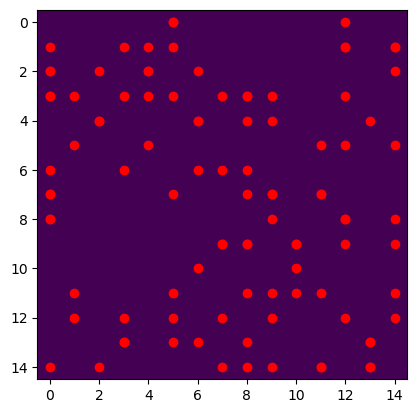

In [3]:
fig_label = "test"

use_centering = True
# use_centering = False

use_whitening = True
# use_whitening = False

truncate_spectrum = True
# truncate_spectrum = False

# denoise_diagonal = True
denoise_diagonal = False

use_eco_init = True
# use_eco_init = False

fig_label = "zerolag"
n_lags = 0
# fig_label = "onelag"
# n_lags = 1
# fig_label = "twolag"
# n_lags = 2

lag_time = 1

simulation = True
obs_noise_level = 0.1
fp = 0.005
n_sources = 20

dims = 15, 15
source_size = 1
np.random.seed(5)
locs = (np.random.rand(100, 2) * dims[0]).clip(0).astype(int)
locs = remove_duplicate_rows(locs)

# dims = 20, 20
# source_size = 2
# n_sources = 2
# locs = (np.random.rand(2, 2) * dims[0]).clip(0).astype(int)
# # locs[0,0] = 6
# # locs[0,1] = 10
# # locs[1,0] = 14
# # locs[1,1] = 10
# locs[0,0] = 9
# locs[0,1] = 10
# locs[1,0] = 10
# locs[1,1] = 10

plt.imshow(np.zeros(dims))
plt.scatter(locs[:, 0], locs[:, 1], c="r")
plt.show()

# simulation = False
# n_sources = 15
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/demoMovie.tif"
# # path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/dendrites_rect.tif"


r.shape = (6,)
z.shape = (6, 6)
spatial_footprints.shape = (20, 15, 15)
added_source = 20


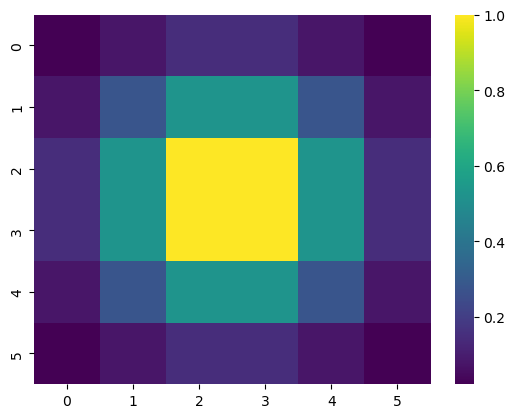

In [4]:
# S = ARProcessMovie(
#     n_timepoints=1_000,
#     n_components=n_sources,
#     ar_noise_sigma=0.1,
#     obs_noise_sigma=obs_noise_level,
#     movie_dims=dims,
#     component_size=source_size,
#     component_locs=locs,
# )

S = ARProcessMovie(
    n_timepoints=2_000,
    n_components=n_sources,
    ar_noise_sigma=0.05,
    obs_noise_sigma=obs_noise_level,
    movie_dims=dims,
    component_size=source_size,
    component_locs=locs,
    rise_constant = 2.,
    decay_constant = 0.97,
    # baselines=[1, 1],
    firing_probability=fp,
)

sns.heatmap(S.kernel, cmap="viridis")

fname = os.path.join(caiman_datadir(), 'example_movies', '/Users/rshang/Work/caiman/mesmerize-core/exp_data/ToySim2D.tif')
imwrite(fname, S.movie)

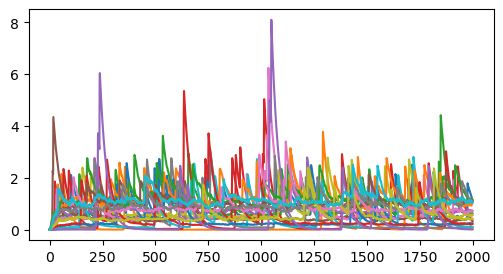

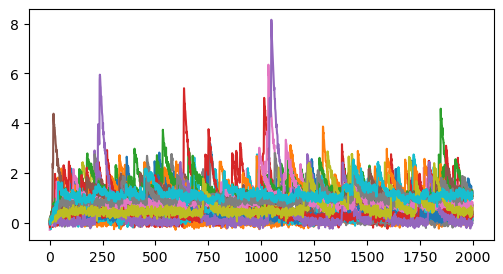

In [5]:
traces = S.traces
traces_obs = S.traces_obs

fig, ax = plt.subplots(figsize=(6, 3))
for src in range(0,len(traces)):
    ax.plot(traces[src])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/truth_trace_{fig_label}.png')
plt.show()

fig, ax = plt.subplots(figsize=(6, 3))
for src in range(0,len(traces_obs)):
    ax.plot(traces_obs[src])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/observed_trace_{fig_label}.png')
plt.show()

In [6]:
source_footprints = S.source_footprints
# source_footprints = S.source_footprints[:, ::2, ::2]
print (f"source_footprints.shape = {source_footprints.shape}")

source_footprints.shape = (20, 15, 15)


In [7]:
movie = S.movie
# Convert the data type to float32
movie = movie.astype(np.float32)
# movie = movie.astype(np.float32)[:, ::2, ::2]
print (movie.shape)

(2000, 15, 15)


In [8]:
if not simulation:

    # movie = tifffile.imread(path)[:]
    # movie = tifffile.imread(path)[:, ::2, ::2]
    # movie = tifffile.imread(path)[:2000, :, :]
    movie = tifffile.imread(path)[:2000, ::2, ::2]

    # Convert the data type to float32
    movie = movie.astype(np.float32)
    
    # n_pix_x = movie.shape[2]
    # n_pix_y = movie.shape[1]
    # n_frame = movie.shape[0]
    
    # n_pix_x_small = int(n_pix_x/3.)
    # n_pix_y_small = int(n_pix_y/3.)
    # small_movie = movie[:, n_pix_y_small:2*n_pix_y_small, n_pix_x_small:2*n_pix_x_small]
    
    # # Convert the data type to float32
    # movie = small_movie.astype(np.float32)
    
    print (movie.shape)

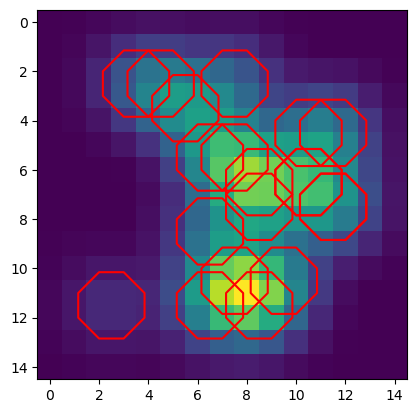

In [9]:
# fpl.ImageWidget(movie).show()

plt.imshow(movie.mean(axis=0))
if simulation:
    truth_levels = [0.60]
    for src in range(0,n_sources):
        plt.contour(source_footprints[src], levels=truth_levels, colors='r')
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/data_image_{fig_label}.png')

In [10]:
from skophys.preprocessing import UnVectorizer, Vectorizer

unvec = UnVectorizer(movie.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie)

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


X.shape = (225, 2000)
P.shape = (1, 225, 2000)


<Axes: >

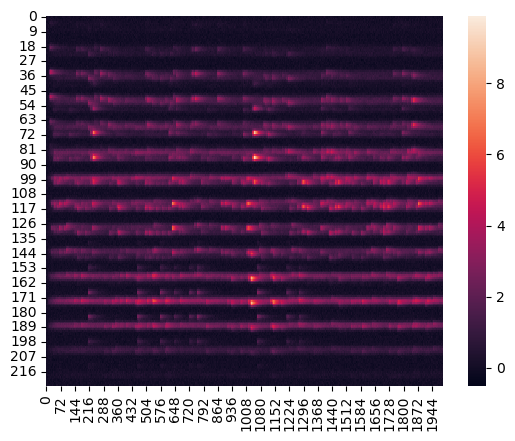

In [11]:
n_pixels = X.shape[0]
n_time_steps = X.shape[1]

P = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
for lag in range(0,n_lags+1):
    for col in range(0,n_time_steps-n_lags*lag_time):
        P[lag,:,col] = X[:,col+lag*lag_time]

print (f"X.shape = {X.shape}")
print (f"P.shape = {P.shape}")
sns.heatmap(P[n_lags,:, :])

In [12]:
def eigen_decomposition(M):
    # output eigenvalues and eigenvectors sorted by eigenvalues
    
    eigenvalues, eigenvectors = np.linalg.eig(M)
    eigenvalues = np.real(eigenvalues)
    eigenvectors = np.real(eigenvectors)
    
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]
    print (f"eigenvectors.shape = {eigenvectors.shape}")

    return eigenvalues, eigenvectors

In [13]:
def covariance_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    T = X.shape[1]
    COV = X @ X.T / float(T)
    
    return COV

def similarity_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    N = X.shape[0]
    COV = X.T @ X / float(N)
    
    return COV

In [14]:
def centered_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    X_mean = X.mean(axis=0, keepdims=True) # has a shape of N x 1
    print (f"X.shape = {X.shape}")
    print (f"X_mean.shape = {X_mean.shape}")

    return X - X_mean

def whitened_matrix(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    # COV shape = (N, N)
    COV = covariance_matrix(X0)
    S, U = eigen_decomposition(COV)

    S_eco = S[:]
    U_eco = U[:, :]
    if truncate_spectrum:
        S_eco = S[:k]
        U_eco = U[:, :k]

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_sqrt_S = np.diag(1.0 / np.sqrt(S_eco + epsilon))

    # whitening matrix W shape (N, N)
    W = U_eco @ inv_sqrt_S @ U_eco.T

    # whitened data shape (N, T)
    Xw = W @ X

    return Xw

def whitened_matrix_T(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    # SIM shape = (T, T)
    SIM = similarity_matrix(X0)
    S, U = eigen_decomposition(SIM)
    
    S_eco = S[:]
    U_eco = U[:, :]
    if truncate_spectrum:
        S_eco = S[:k]
        U_eco = U[:, :k]
    
    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_sqrt_S = np.diag(1.0 / np.sqrt(S_eco + epsilon))

    # whitening matrix W shape (N, N)
    W = U_eco @ inv_sqrt_S @ U_eco.T

    # whitened data shape (N, T)
    Xw = X @ W

    return Xw

def eco_whitened_matrix(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")

    U, S, VT = np.linalg.svd(X0, full_matrices=True)
    S_eco = S[:k]
    U_eco = U[:, :k]
    VT_eco = VT[:k, :]

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_S = np.diag(1.0 / (S_eco + epsilon))

    print (f"inv_S.shape = {inv_S.shape}")

    # Create a zero matrix of shape (k, num_extra_cols)
    num_extra_cols = X.shape[0] - k
    zeros = np.zeros((k, num_extra_cols))
    
    inv_S_reshape = np.hstack((inv_S, zeros))

    print (f"inv_S_reshape.shape = {inv_S_reshape.shape}")

    # whitening matrix W shape (N, N)
    W = inv_S_reshape @ U.T

    print (f"W.shape = {W.shape}")

    # whitened data shape (N, T)
    Xw = W @ X

    return Xw

def eco_whitened_matrix_T(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")

    U, S, VT = np.linalg.svd(X0, full_matrices=True)
    S_eco = S[:k]
    U_eco = U[:, :k]
    VT_eco = VT[:k, :]

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_S = np.diag(1.0 / (S_eco + epsilon))

    print (f"inv_S.shape = {inv_S.shape}")

    # Create a zero matrix of shape (num_extra_rows, k)
    num_extra_rows = X.shape[1] - k
    zeros = np.zeros((num_extra_rows, k))
    
    inv_S_reshape = np.vstack((inv_S, zeros))

    print (f"inv_S_reshape.shape = {inv_S_reshape.shape}")
    print (f"VT.shape = {VT.shape}")

    # whitening matrix W shape (T, T)
    W = VT.T @ inv_S_reshape

    print (f"W.shape = {W.shape}")

    # whitened data shape (N, T)
    Xw = X @ W

    return Xw


In [15]:
Pc = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
for lag in range(0,n_lags+1):
    Pc[lag,:,:] = centered_matrix(P[lag,:,:])

X.shape = (225, 2000)
X_mean.shape = (1, 2000)


In [16]:
if n_lags==0:
    Z0 = P[0].copy()
if n_lags==1:
    Z0 = np.vstack((P[0], P[1]))
if n_lags==2:
    Z0 = np.vstack((P[0], P[1], P[2]))
if n_lags==3:
    Z0 = np.vstack((P[0], P[1], P[2], P[3]))
if n_lags==4:
    Z0 = np.vstack((P[0], P[1], P[2], P[3], P[4]))
if n_lags==5:
    Z0 = np.vstack((P[0], P[1], P[2], P[3], P[4], P[5]))

eigenvectors.shape = (2000, 2000)


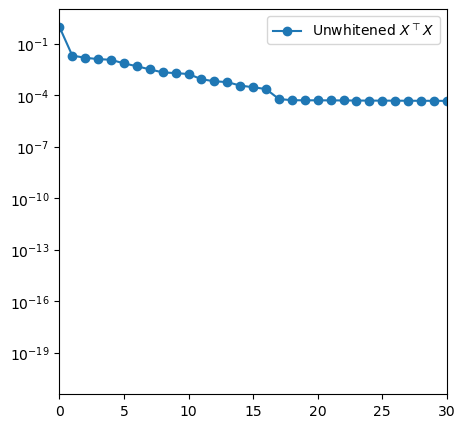

In [17]:
# PTP = similarity_matrix(Pc[0])
PTP = similarity_matrix(P[0])
S_PTP, U_PTP = eigen_decomposition(PTP)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(S_PTP[:] / S_PTP.max(),'o-', label="Unwhitened $X^{\\top}X$")
# ax.plot(S_PPT[:] / S_PPT.max(),'o-', label="Unwhitened $XX^{\\top}$")
ax.legend()
ax.set_yscale('log')
# plt.ylim(0.0001, 1.5)
plt.xlim(0, 30)
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/XTX_spectrum_src{src}_{fig_label}.png')
plt.show()

[0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
noise_threshold = 0.6687706202003463
n_sources_final = 16


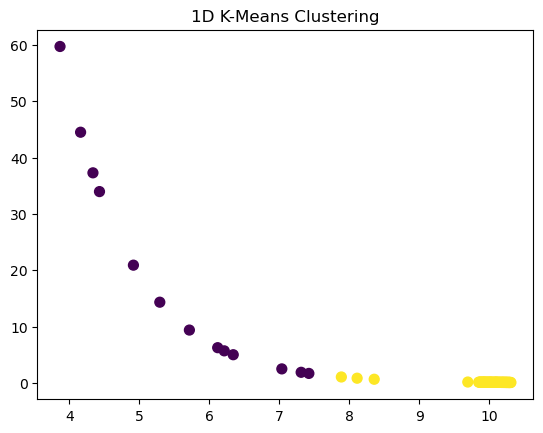

n_sources_kmeans = 15
k = 20


In [18]:
def kmeans_1d(data, k, max_iters=100, tol=1e-4):
    # Randomly initialize k cluster centers
    centroids = np.random.choice(data, k, replace=False)
    centroids[0] = np.max(data)
    for entry in range(1,k):
        centroids[entry] = np.min(data)

    for _ in range(max_iters):
        # Assign each point to the nearest centroid
        distances = np.abs(data[:, np.newaxis] - centroids[np.newaxis, :])
        labels = np.argmin(distances, axis=1)

        # Compute new centroids
        new_centroids = np.array([data[labels == i].mean() if np.any(labels == i) else centroids[i] 
                                  for i in range(k)])

        # Check for convergence
        if np.all(np.abs(new_centroids - centroids) < tol):
            break

        centroids = new_centroids

    return labels, centroids

max_entries = 100
starting_entry = 1
labels, centroids = kmeans_1d(np.log(S_PTP[starting_entry:max_entries] / S_PTP.max()), k=2)
print (labels)

dim_ratio = n_time_steps / n_pixels
n_sources_init = np.sum(labels == 0) + starting_entry + 1
max_noise_S = S_PTP[n_sources_init+1] 
noise_variance = max_noise_S / np.square(1. + np.sqrt(dim_ratio))
noise_threshold = noise_variance * np.square(1. + np.sqrt(dim_ratio))
print (f"noise_threshold = {noise_threshold}")

n_sources_final = 0
S_PTP_dim = len(S_PTP)
for entry in range(0,S_PTP_dim):
    if S_PTP[entry] > (noise_threshold):
        n_sources_final += 1
print (f"n_sources_final = {n_sources_final}")

# Plotting
plt.scatter(-np.log(S_PTP[starting_entry:max_entries] / S_PTP.max()), S_PTP[starting_entry:max_entries], c=labels, cmap='viridis', s=50)
# plt.scatter(centroids, np.zeros_like(centroids), color='red', marker='x', s=200)
plt.title('1D K-Means Clustering')
plt.show()

n_sources_kmeans = np.sum(labels == 0) + starting_entry + 1
# n_sources_kmeans = n_sources_final

print (f"n_sources_kmeans = {n_sources_kmeans}")
if not simulation:
    n_sources = n_sources_kmeans
    
k = n_sources
print (f"k = {k}")

[[1.00629478e-02 1.72019542e-04 5.51554010e-04 ... 2.96913515e-03
  4.11647735e-03 3.73460904e-03]
 [1.72019542e-04 9.25853077e-03 1.14002967e-03 ... 1.24177048e-02
  1.19807540e-02 1.22342844e-02]
 [5.51554010e-04 1.14002967e-03 1.10395977e-02 ... 3.72277074e-02
  3.69032541e-02 3.54673706e-02]
 ...
 [2.96913515e-03 1.24177048e-02 3.72277074e-02 ... 9.35659844e-01
  9.19052522e-01 9.02062934e-01]
 [4.11647735e-03 1.19807540e-02 3.69032541e-02 ... 9.19052522e-01
  9.24890811e-01 8.96814054e-01]
 [3.73460904e-03 1.22342844e-02 3.54673706e-02 ... 9.02062934e-01
  8.96814054e-01 8.89992149e-01]]


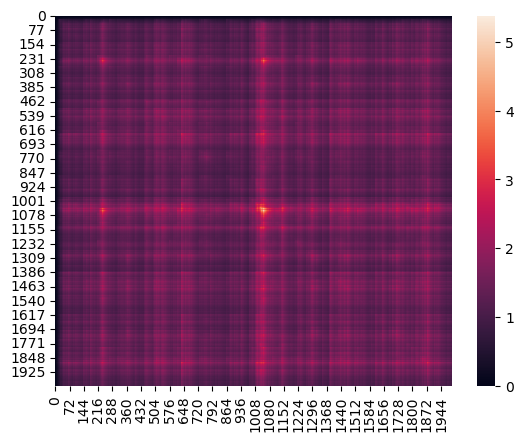

In [19]:
SIM = similarity_matrix(P[0,:,:])
print (SIM)
sns.heatmap(SIM[:, :])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/original_sim_{fig_label}.png')

[[ 1.04412100e-02 -6.01857557e-05 -1.03836268e-04 ... -7.84808316e-06
   2.22515167e-04  2.34919430e-04]
 [-6.01857557e-05  1.06013520e-02  1.16503058e-03 ... -3.58173290e-04
  -1.27806360e-04 -2.16550850e-05]
 [-1.03836268e-04  1.16503058e-03  1.45815073e-02 ...  8.21308708e-05
  -3.25087703e-04 -2.71194959e-04]
 ...
 [-7.84808316e-06 -3.58173290e-04  8.21308708e-05 ...  1.06732618e-02
  -1.59163496e-05  2.97520874e-04]
 [ 2.22515167e-04 -1.27806360e-04 -3.25087703e-04 ... -1.59163496e-05
   1.05101947e-02  6.83720901e-06]
 [ 2.34919430e-04 -2.16550850e-05 -2.71194959e-04 ...  2.97520874e-04
   6.83720901e-06  9.89487069e-03]]


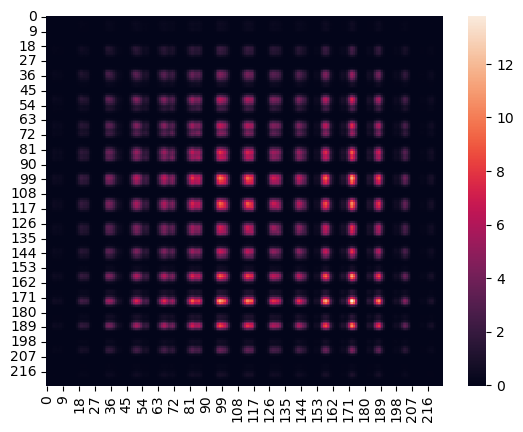

In [20]:
COV = covariance_matrix(P[0,:,:])
print (COV)
sns.heatmap(COV[:, :])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/original_cov_{fig_label}.png')

X.shape = (225, 2000)
inv_S.shape = (20, 20)
inv_S_reshape.shape = (20, 225)
W.shape = (20, 225)
X.shape = (225, 2000)
inv_S.shape = (20, 20)
inv_S_reshape.shape = (2000, 20)
VT.shape = (2000, 2000)
W.shape = (2000, 20)
eigenvectors.shape = (225, 225)
P.shape = (1, 225, 2000)
Pw.shape = (1, 225, 2000)
Pw_eco.shape = (1, 20, 2000)
Pw_eco_T.shape = (1, 225, 20)
[[ 0.02098717  0.00074379 -0.00591102 ...  0.00270327  0.01348411
   0.00160954]
 [ 0.00074379  0.00840768  0.0099393  ...  0.00737701  0.00274742
   0.00759169]
 [-0.00591102  0.0099393   0.02029705 ...  0.01521476 -0.00534707
   0.01237295]
 ...
 [ 0.00270327  0.00737701  0.01521476 ...  0.01800167 -0.00191275
   0.01285999]
 [ 0.01348411  0.00274742 -0.00534707 ... -0.00191275  0.01318556
   0.00045128]
 [ 0.00160954  0.00759169  0.01237295 ...  0.01285999  0.00045128
   0.01075111]]


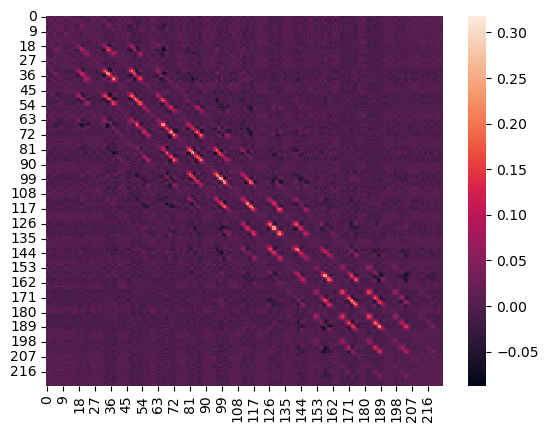

In [21]:
Pw = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
Pw_eco = np.zeros((n_lags+1,k,n_time_steps-n_lags*lag_time))
Pw_eco_T = np.zeros((n_lags+1,n_pixels,k))
for lag in range(0,n_lags+1):
    if use_centering:
        Pw_eco[lag,:,:] = eco_whitened_matrix(P[lag,:,:],Pc[lag,:,:],k)
        Pw_eco_T[lag,:,:] = eco_whitened_matrix_T(P[lag,:,:],Pc[lag,:,:],k)
        Pw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],k)
    else:
        Pw_eco[lag,:,:] = eco_whitened_matrix(P[lag,:,:],P[lag,:,:],k)
        Pw_eco_T[lag,:,:] = eco_whitened_matrix_T(P[lag,:,:],P[lag,:,:],k)
        Pw[lag,:,:] = whitened_matrix(P[lag,:,:],P[lag,:,:],k)
print (f"P.shape = {P.shape}")
print (f"Pw.shape = {Pw.shape}")
print (f"Pw_eco.shape = {Pw_eco.shape}")
print (f"Pw_eco_T.shape = {Pw_eco_T.shape}")

# verify that Pw is whitened data
COV = covariance_matrix(Pw[0,:,:])
print (COV)
sns.heatmap(COV[:, :])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/whitened_PTP_{fig_label}.png')

In [22]:
if n_lags>0:
    cross_correlation = Pw[1,:,:] @ Pw[0,:,:].T
    sns.heatmap(cross_correlation[:, :])
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/whitened_ZTZ_{fig_label}.png')

In [23]:
if use_whitening:
    if n_lags==0:
        Z = Pw[0].copy()
    if n_lags==1:
        Z = np.vstack((Pw[0], Pw[1]))
    if n_lags==2:
        Z = np.vstack((Pw[0], Pw[1], Pw[2]))
    if n_lags==3:
        Z = np.vstack((Pw[0], Pw[1], Pw[2], Pw[3]))
    if n_lags==4:
        Z = np.vstack((Pw[0], Pw[1], Pw[2], Pw[3], Pw[4]))
    if n_lags==5:
        Z = np.vstack((Pw[0], Pw[1], Pw[2], Pw[3], Pw[4], Pw[5]))
else:
    if n_lags==0:
        Z = P[0].copy()
    if n_lags==1:
        Z = np.vstack((P[0], P[1]))
    if n_lags==2:
        Z = np.vstack((P[0], P[1], P[2]))
    if n_lags==3:
        Z = np.vstack((P[0], P[1], P[2], P[3]))
    if n_lags==4:
        Z = np.vstack((P[0], P[1], P[2], P[3], P[4]))
    if n_lags==5:
        Z = np.vstack((P[0], P[1], P[2], P[3], P[4], P[5]))
    
ZTZ = similarity_matrix(Z)
ZZT = covariance_matrix(Z)
print (f"ZTZ.shape = {ZTZ.shape}")
print (f"ZZT.shape = {ZZT.shape}")
if denoise_diagonal:
    # diagonal_mean = np.mean(np.diag(ZTZ))
    # ZTZ = ZTZ - np.identity(ZTZ.shape[0]) * diagonal_mean
    # ZTZ = ZTZ.clip(0)
    np.fill_diagonal(ZTZ, 0.)
    np.fill_diagonal(ZZT, 0.)

ZTZ.shape = (2000, 2000)
ZZT.shape = (225, 225)


eigenvectors.shape = (2000, 2000)
eigenvectors.shape = (225, 225)


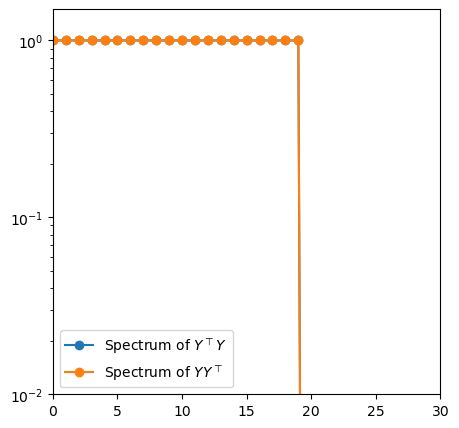

In [24]:
S_ZTZ, U_ZTZ = eigen_decomposition(ZTZ)
S_ZZT, U_ZZT = eigen_decomposition(ZZT)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(S_ZTZ[:] / S_ZTZ.max(),'o-', label="Spectrum of $Y^{\\top}Y$")
ax.plot(S_ZZT[:] / S_ZZT.max(),'o-', label="Spectrum of $YY^{\\top}$")
ax.legend()
ax.set_yscale('log')
plt.ylim(0.01, 1.5)
plt.xlim(0, 30)
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/YYT_spectrum_src{src}_{fig_label}.png')
plt.show()

In [25]:
from sklearn.utils.extmath import randomized_svd
def nnsvd(X_init, k, eps: float = 1e-6):
    U, S, V = randomized_svd(X_init, n_components=k)
    W = np.zeros_like(U)
    H = np.zeros_like(V)
    
    # The leading singular triplet is non-negative
    # so it can be used as is for initialization.
    W[:, 0] = np.sqrt(S[0]) * np.abs(U[:, 0])
    H[0, :] = np.sqrt(S[0]) * np.abs(V[0, :])
    
    for j in range(1, k):
        x, y = U[:, j], V[j, :]
    
        # extract positive and negative parts of column vectors
        x_p, y_p = np.maximum(x, 0), np.maximum(y, 0)
        x_n, y_n = np.abs(np.minimum(x, 0)), np.abs(np.minimum(y, 0))
    
        # and their norms
        x_p_nrm, y_p_nrm = np.linalg.norm(x_p, ord=2), np.linalg.norm(y_p, ord=2)
        x_n_nrm, y_n_nrm = np.linalg.norm(x_n, ord=2), np.linalg.norm(y_n, ord=2)
    
        m_p, m_n = x_p_nrm * y_p_nrm, x_n_nrm * y_n_nrm
    
        # choose update
        if m_p > m_n:
            u = x_p / x_p_nrm
            v = y_p / y_p_nrm
            sigma = m_p
        else:
            u = x_n / x_n_nrm
            v = y_n / y_n_nrm
            sigma = m_n
    
        lbd = np.sqrt(S[j] * sigma)
        W[:, j] = lbd * u
        H[j, :] = lbd * v
    
    W[W < eps] = 0
    H[H < eps] = 0
    
    return W, H.T


In [26]:
# S, U = eigen_decomposition(ZTZ)
# Uk = U[:,:k]
# Sk = np.diag(np.sqrt(S[:k]))
# H_init = np.abs(Uk @ Sk)

H_init = 2 * np.sqrt(np.mean(np.mean(ZTZ) / k)) * np.random.rand(ZTZ.shape[0], k)
W_init = 2 * np.sqrt(np.mean(np.mean(ZZT) / k)) * np.random.rand(ZZT.shape[0], k)

print (f"H_init.shape = {H_init.shape}")
print (f"W_init.shape = {W_init.shape}")
print (f"Pw_eco_T.shape = {Pw_eco_T.shape}")

if use_eco_init:

    W_init, H_init = nnsvd(Z,k)
    
    # H_init = np.zeros((n_time_steps-n_lags*lag_time,k))
    # W_init = np.zeros(((n_lags+1)*n_pixels,k))
    # for lag in range(0,n_lags+1):
    #     H_init += np.abs(Pw_eco[lag,:,:].T)
    #     W_init[lag*n_pixels:(lag+1)*n_pixels,:] += np.abs(Pw_eco_T[lag,:,:])



H_init.shape = (2000, 20)
W_init.shape = (225, 20)
Pw_eco_T.shape = (1, 225, 20)


In [27]:
from tqdm.notebook import tqdm

eta = 0.1
error_stop = 1e-4
n_iterations = 5_000
error_log = np.zeros(n_iterations)

H = H_init.T
H = H.clip(0)
W = W_init
W = W.clip(0)

N = H.shape[0]
T = H.shape[1]

epsilon = 1e-10
epsilon_mtx = np.ones_like(H@H.T@H) * epsilon

# beta = 0.001
# beta = 0.01
# beta = 0.1
beta = 1.0
# beta = 10.0
# beta = 100.
# beta = 1000.

for n_iter in tqdm(range(n_iterations)):
    H_old = H.copy()
    W_old = W.copy()

    # gamma = H_old @ ZTZ / (beta * (H_old @ H_old.T @ H_old / float(T)) + epsilon_mtx)
    # H = H_old * (1-eta) + eta * H_old * gamma

    H = H_old + eta * (H_old @ ZTZ - beta * H_old @ H_old.T @ H_old / float(T))
    H = H.clip(0)  

    W = W_old + eta * (ZZT @ W_old - beta * W_old @ W_old.T @ W_old / float(N))
    W = W.clip(0)
    
    er = np.divide(np.abs(W - W_old), np.abs(W_old + epsilon)).mean() / eta
    error_log[n_iter] = er
    # print (f"er = {er}")

    if er < error_stop:
        break

  0%|          | 0/5000 [00:00<?, ?it/s]

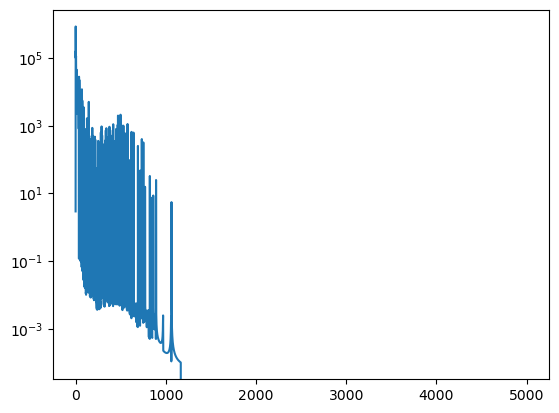

In [28]:
plt.plot(error_log)
plt.yscale('log')
# plt.xscale('log')
plt.show()

[[ 0.02098717  0.00074379 -0.00591102 ...  0.00270327  0.01348411
   0.00160954]
 [ 0.00074379  0.00840768  0.0099393  ...  0.00737701  0.00274742
   0.00759169]
 [-0.00591102  0.0099393   0.02029705 ...  0.01521476 -0.00534707
   0.01237295]
 ...
 [ 0.00270327  0.00737701  0.01521476 ...  0.01800167 -0.00191275
   0.01285999]
 [ 0.01348411  0.00274742 -0.00534707 ... -0.00191275  0.01318556
   0.00045128]
 [ 0.00160954  0.00759169  0.01237295 ...  0.01285999  0.00045128
   0.01075111]]


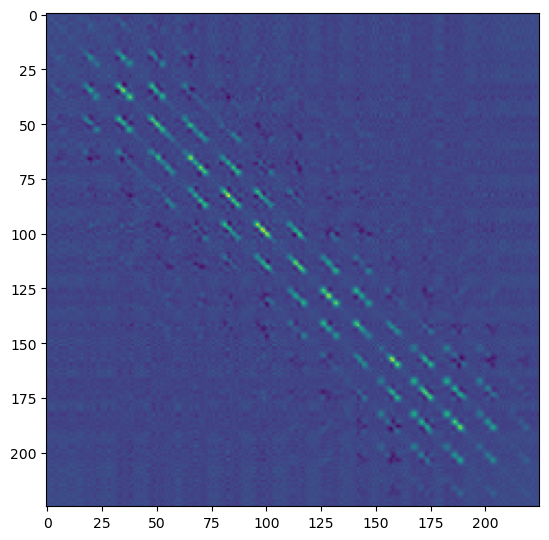

In [29]:
print (ZZT)

fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
ax.imshow(ZZT[:n_pixels,n_lags*n_pixels:,])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/ZZT_{fig_label}.png')
plt.show()

[[0.01938953 0.         0.         ... 0.         0.01472886 0.        ]
 [0.         0.00683649 0.01026174 ... 0.00855632 0.         0.00783542]
 [0.         0.01026174 0.0168402  ... 0.01284326 0.         0.01176117]
 ...
 [0.         0.00855632 0.01284326 ... 0.01070882 0.         0.00980656]
 [0.01472886 0.         0.         ... 0.         0.01118847 0.        ]
 [0.         0.00783542 0.01176117 ... 0.00980656 0.         0.00898032]]


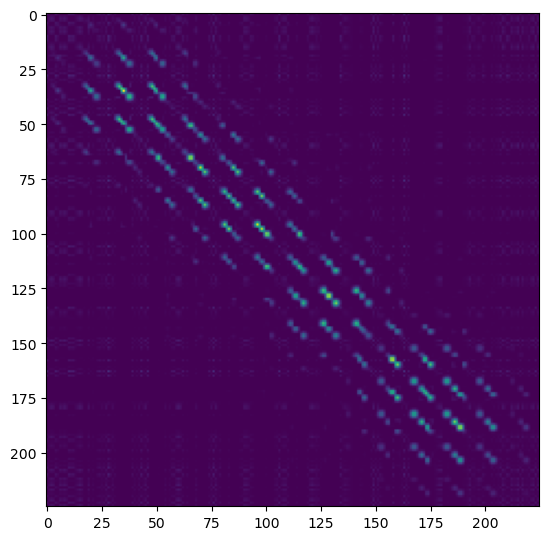

In [30]:
WWT = covariance_matrix(W)
print (WWT)

fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
ax.imshow(np.abs(WWT[:n_pixels,n_lags*n_pixels:]))
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/WWT_{fig_label}.png')
plt.show()

In [31]:
S_solved_by_sim = H
A_concatenated = Z @ H.T
# A_concatenated = Z0 @ H.T
print (f"A_concatenated.shape = {A_concatenated.shape}")

A_solved_by_sim = np.zeros((n_pixels,k))
if n_lags==0:
    A_solved_by_sim += A_concatenated
else:
    for lag in range(0,n_lags+1):
        A_solved_by_sim[:,:] += A_concatenated[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)

S_solved_by_sim = S_solved_by_sim.clip(0)
A_solved_by_sim = A_solved_by_sim.clip(0)

image_array_by_sim = []
for entry in range(0,k):
    snapshot = unvec.transform(A_solved_by_sim[:,entry])
    image_array_by_sim += [snapshot]

A_concatenated.shape = (225, 20)


In [32]:
print (f"W.shape = {W.shape}")
A_solved_by_cov = np.zeros((n_pixels,k))
if n_lags==0:
    A_solved_by_cov += W
else:
    for lag in range(0,n_lags+1):
        A_solved_by_cov[:,:] += W[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)
S_solved_by_cov = W.T @ Z

S_solved_by_cov = S_solved_by_cov.clip(0)
A_solved_by_cov = A_solved_by_cov.clip(0)

image_array_by_cov = []
for entry in range(0,k):
    snapshot = unvec.transform(A_solved_by_cov[:,entry])
    image_array_by_cov += [snapshot]

W.shape = (225, 20)


In [33]:
from sklearn.metrics.pairwise import cosine_similarity

S_vec = vectorizer.fit_transform(source_footprints).T
print (f"S_vec.shape = {S_vec.shape}")

if simulation:
    cluster_matching_by_sim = []
    selected_cluster_by_sim = []
    for src in range(0,n_sources):
        max_corr = 0.
        pair_indices = []
        for cluster in range(0,k):
            if cluster in selected_cluster_by_sim: 
                continue
            corr = S_vec[src] @ A_solved_by_sim[:,cluster].T / np.sqrt(1e-5 + A_solved_by_sim[:,cluster] @ A_solved_by_sim[:,cluster].T * S_vec[src] @ S_vec[src].T)
            if corr >= max_corr:
                max_corr = corr
                pair_indices = [src, cluster]
        cluster_matching_by_sim += [pair_indices]
        selected_cluster_by_sim += [pair_indices[1]]
    print (f"cluster_matching = {cluster_matching_by_sim}")

    cluster_matching_by_cov = []
    selected_cluster_by_cov = []
    for src in range(0,n_sources):
        max_corr = 0.
        pair_indices = []
        for cluster in range(0,k):
            if cluster in selected_cluster_by_cov: 
                continue
            corr = S_vec[src] @ A_solved_by_cov[:,cluster].T / np.sqrt(1e-5 + A_solved_by_cov[:,cluster] @ A_solved_by_cov[:,cluster].T * S_vec[src] @ S_vec[src].T)
            if corr >= max_corr:
                max_corr = corr
                pair_indices = [src, cluster]
        cluster_matching_by_cov += [pair_indices]
        selected_cluster_by_cov += [pair_indices[1]]
    print (f"cluster_matching = {cluster_matching_by_cov}")

S_vec.shape = (20, 225)
cluster_matching = [[0, 7], [1, 2], [2, 9], [3, 3], [4, 11], [5, 13], [6, 19], [7, 5], [8, 8], [9, 1], [10, 10], [11, 14], [12, 15], [13, 6], [14, 4], [15, 0], [16, 12], [17, 18], [18, 16], [19, 17]]
cluster_matching = [[0, 7], [1, 2], [2, 9], [3, 3], [4, 11], [5, 6], [6, 8], [7, 5], [8, 10], [9, 1], [10, 13], [11, 12], [12, 0], [13, 4], [14, 17], [15, 16], [16, 19], [17, 15], [18, 18], [19, 14]]


In [34]:
print (X.shape)
print (traces.shape)

S_sorted_by_sim = np.zeros_like(traces)
S_sorted_by_cov = np.zeros_like(traces)

if simulation:
    for src in range(0,n_sources):
        truth_norm = np.sum(traces[src])
        
        cluster = cluster_matching_by_sim[src][1]
        reco_norm = np.sum(S_solved_by_sim[cluster])
        S_solved_by_sim[cluster] = S_solved_by_sim[cluster] * truth_norm / (reco_norm+1e-10)
        S_sorted_by_sim[src,n_lags*lag_time:] = S_solved_by_sim[cluster]

        cluster = cluster_matching_by_cov[src][1]
        reco_norm = np.sum(S_solved_by_cov[cluster])
        S_solved_by_cov[cluster] = S_solved_by_cov[cluster] * truth_norm / (reco_norm+1e-10)
        S_sorted_by_cov[src,n_lags*lag_time:] = S_solved_by_cov[cluster]


(225, 2000)
(20, 2000)


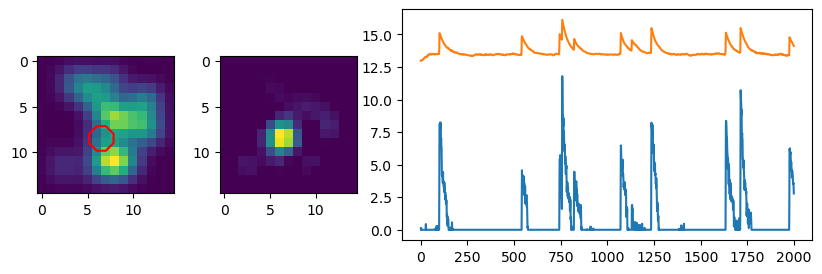

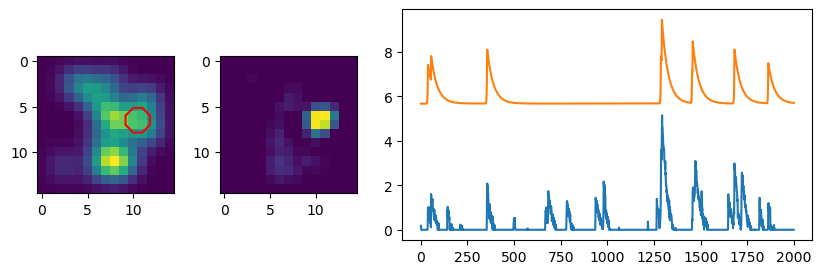

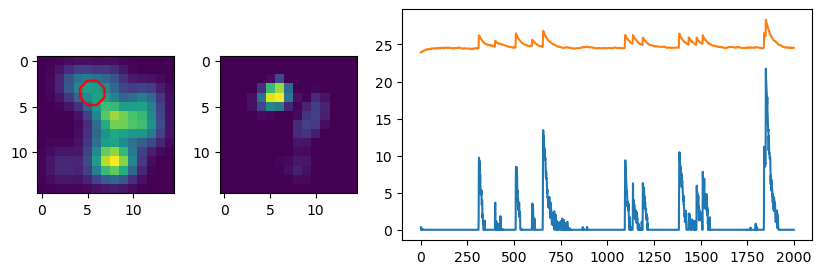

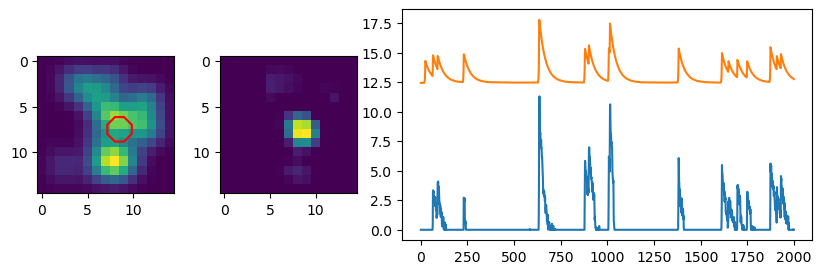

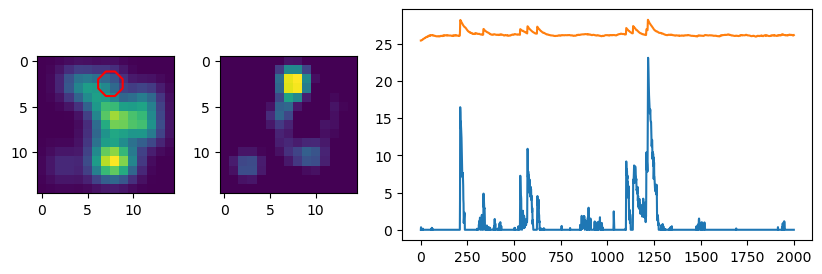

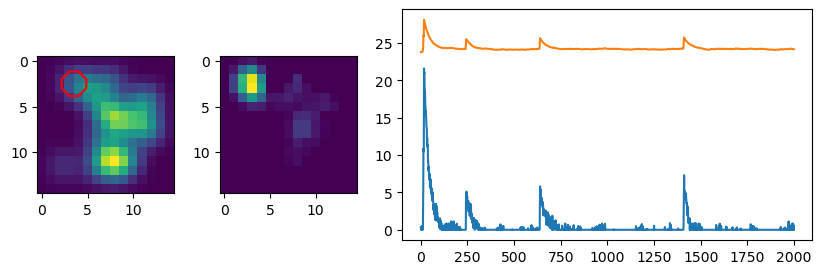

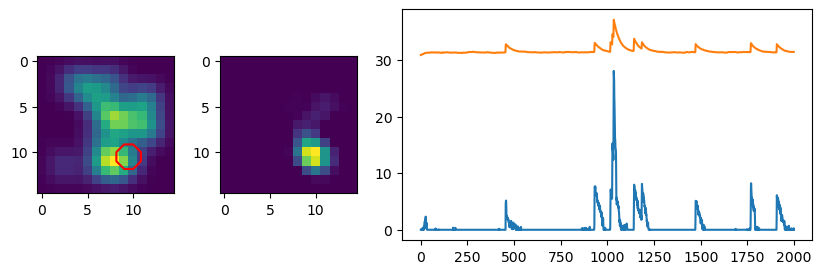

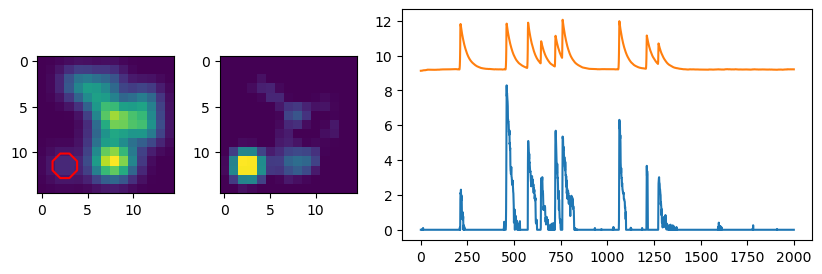

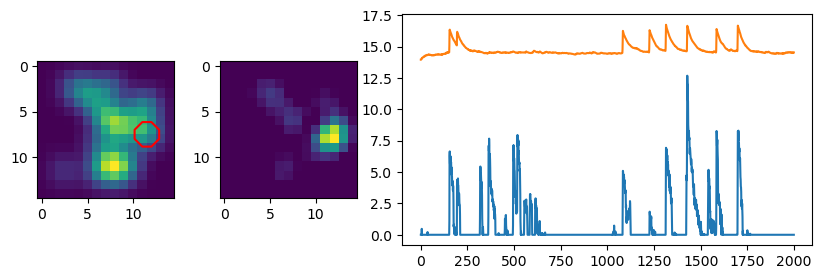

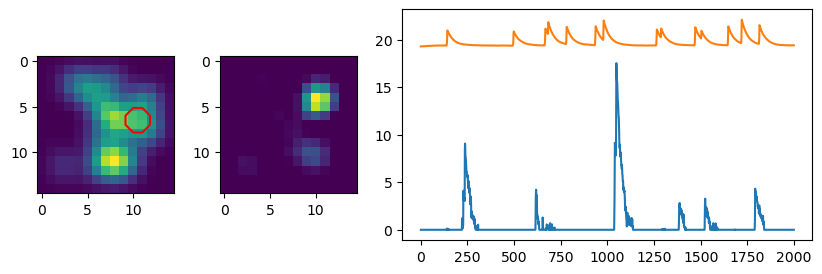

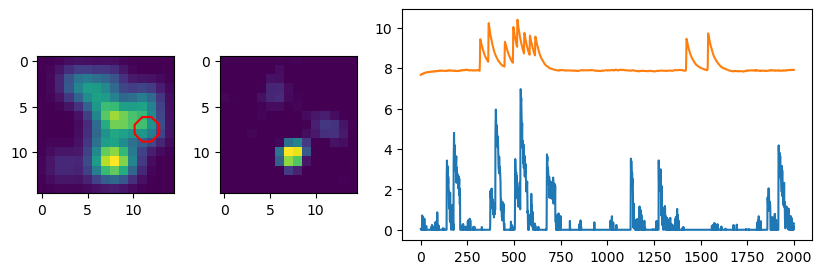

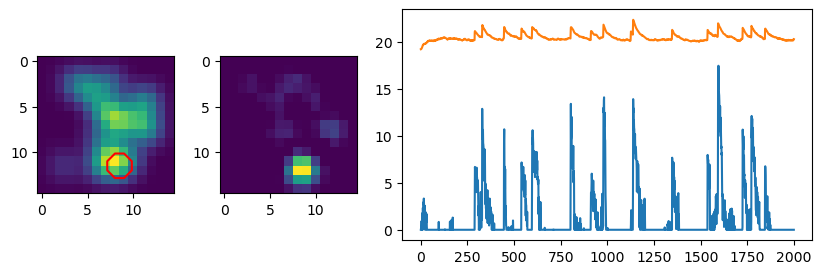

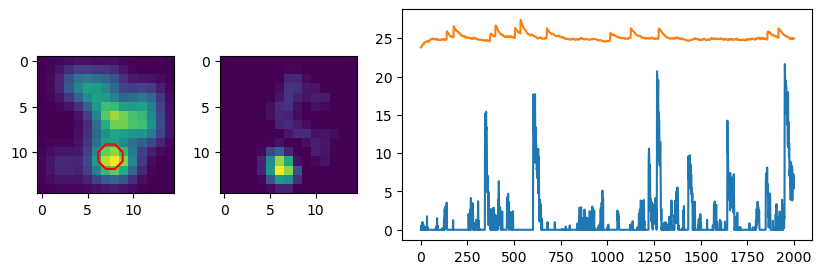

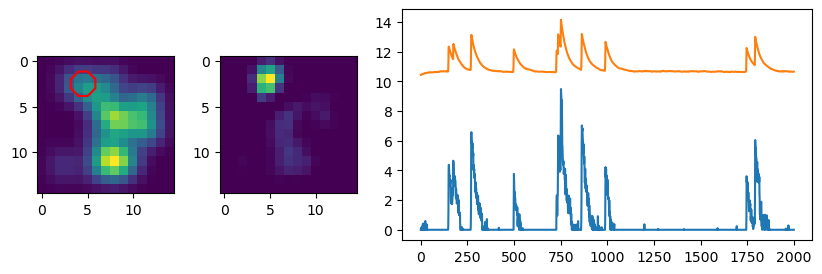

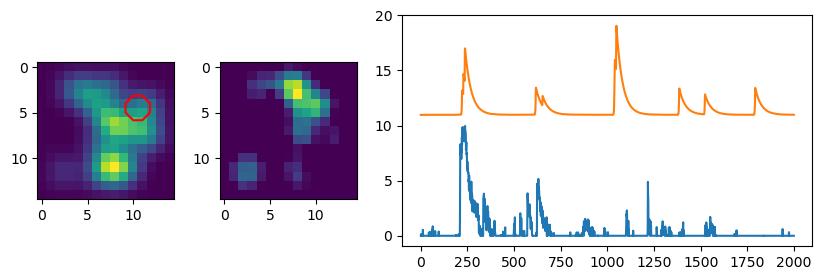

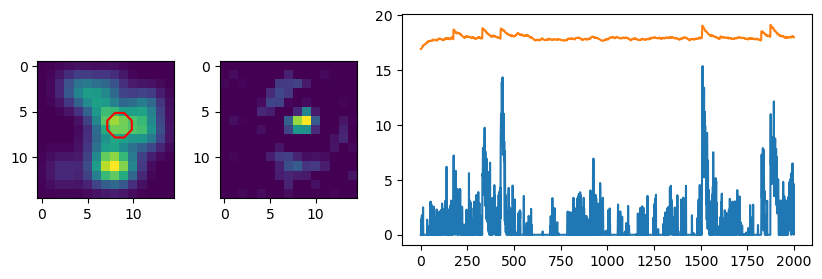

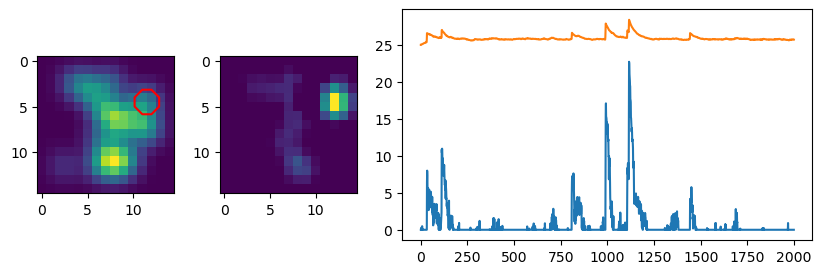

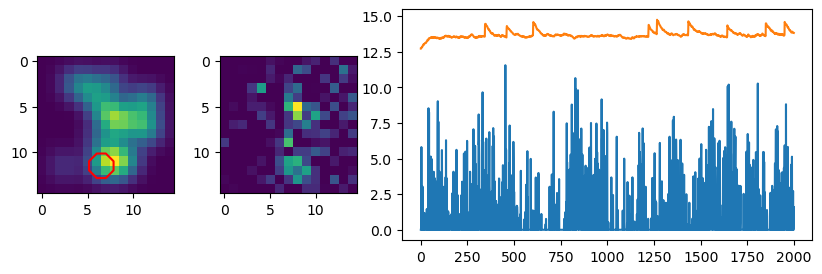

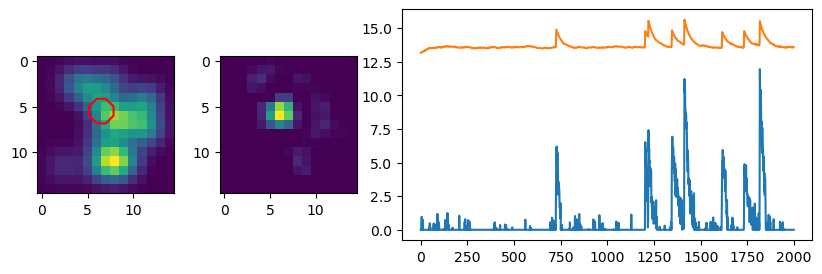

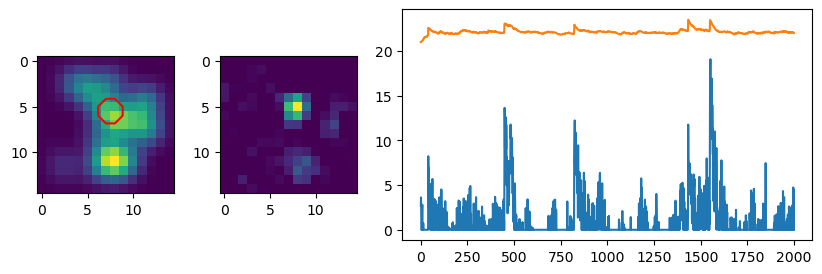

matching_score / truth_score = 0.6077127430869724


In [35]:
matching_score = 0.
truth_score = 0.
if simulation:
    reco_levels = [0.60]
    for src in range(0,n_sources):
        truth_levels = [0.60]
        reco_levels = [0.60*np.max(image_array_by_sim[cluster])]
        fig, ax = plt.subplots(1, 3, figsize=(10, 3), gridspec_kw={'width_ratios': [1, 1, 3]})
        cluster = cluster_matching_by_sim[src][1]
        ax[0].imshow(movie.mean(axis=0))
        ax[0].contour(source_footprints[src], levels=truth_levels, colors='r')
        ax[0].contour(image_array_by_sim[cluster] / np.max(image_array_by_sim[cluster]), levels=reco_levels, colors='w')
        ax[1].imshow(image_array_by_sim[cluster])
        ax[2].plot(S_solved_by_sim[cluster], label="reconstruction")
        ax[2].plot(traces[src] + 1.1*np.max(S_solved_by_sim[cluster]), label="truth")
        # ax[2].legend()
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_by_sim_{fig_label}.png')
        plt.show()

        matching_score += S_solved_by_sim[cluster].T @ traces[src,n_lags*lag_time:]
        truth_score += np.sqrt(traces[src,n_lags*lag_time:].T @ traces[src,n_lags*lag_time:] * S_solved_by_sim[cluster].T @ S_solved_by_sim[cluster])

    print (f"matching_score / truth_score = {matching_score / truth_score}")
else:
    for src in range(0,k):
        reco_levels = [0.30*np.max(image_array_by_sim[src])]
        fig, ax = plt.subplots(1, 3, figsize=(10, 2), gridspec_kw={'width_ratios': [1, 1, 3]})
        ax[0].imshow(movie.mean(axis=0))
        ax[0].contour(image_array_by_sim[src], levels=reco_levels, colors='w')
        ax[1].imshow(image_array_by_sim[src], cmap="Reds")
        ax[2].plot(S_solved_by_sim[src])
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_by_sim_{fig_label}.png')
        plt.show()

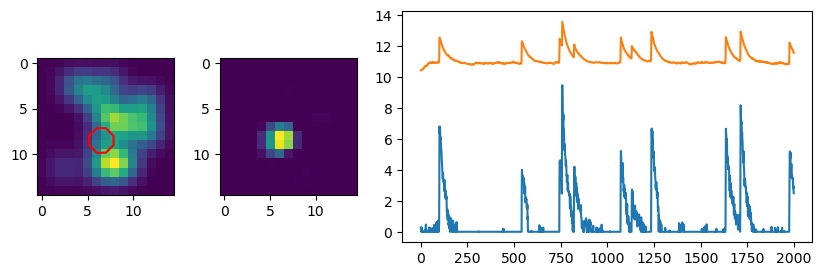

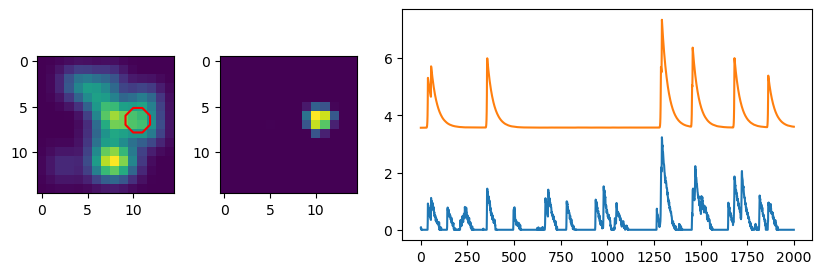

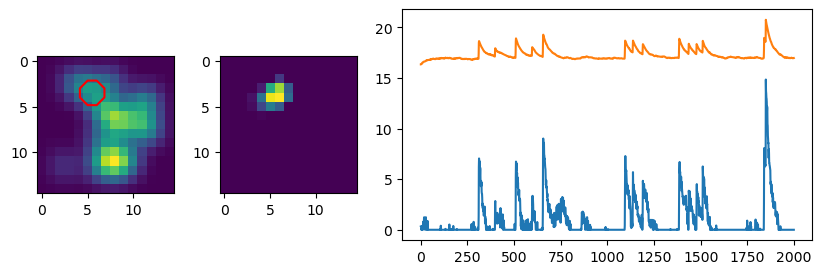

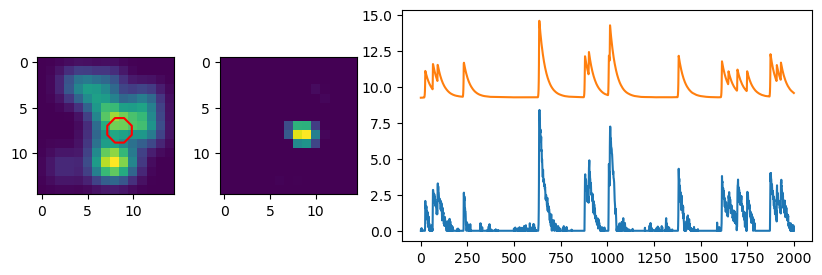

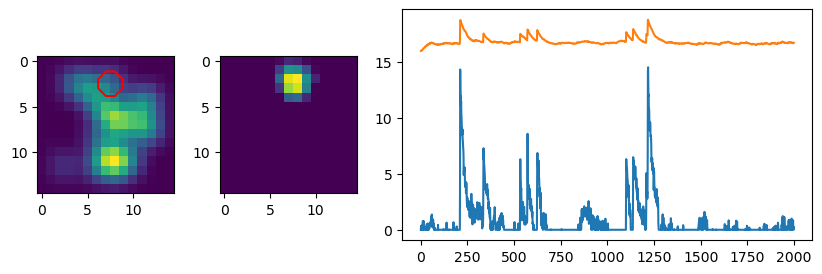

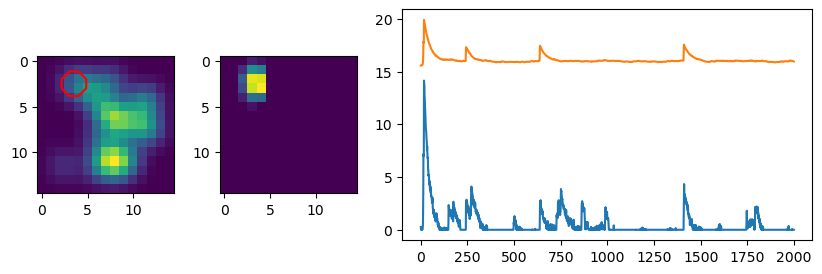

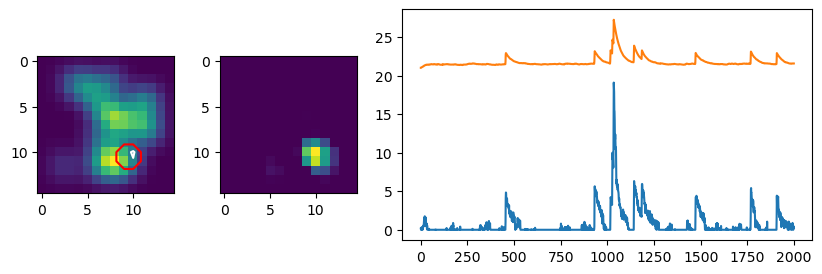

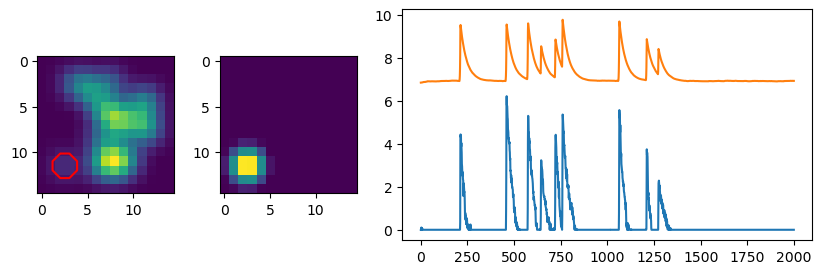

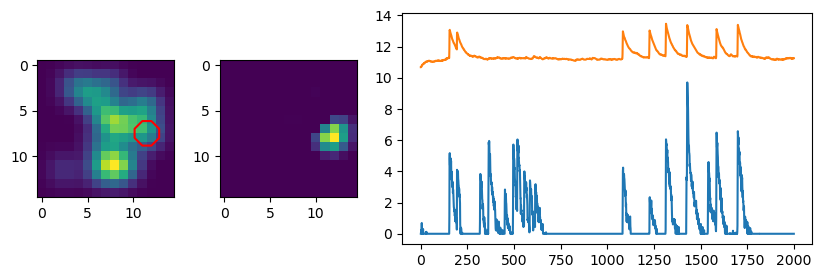

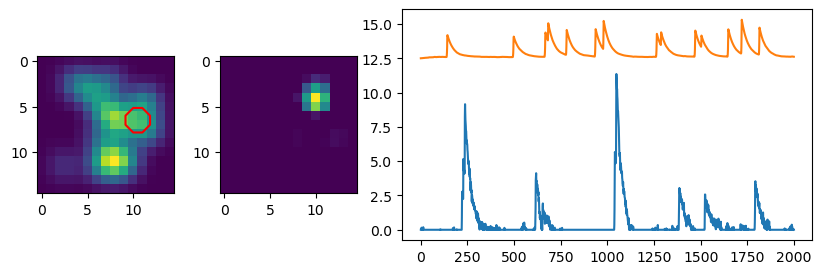

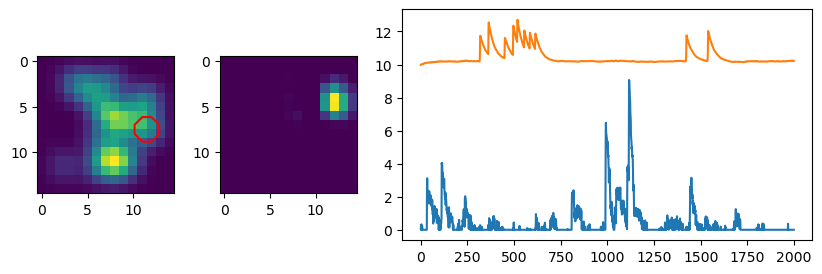

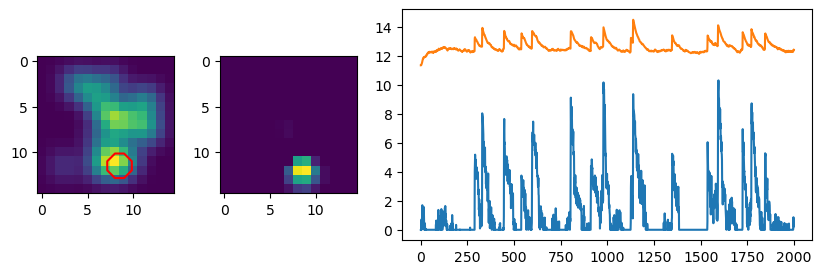

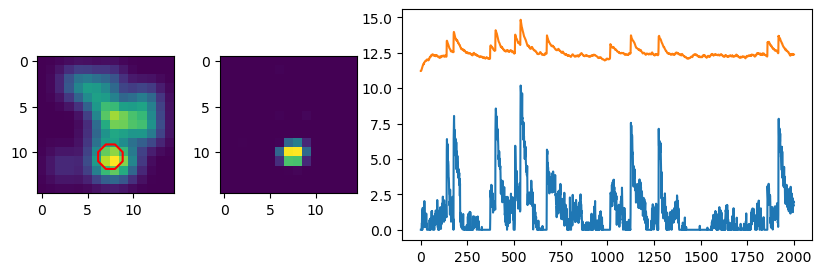

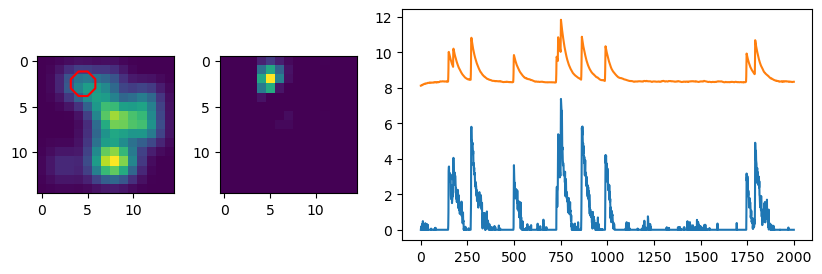

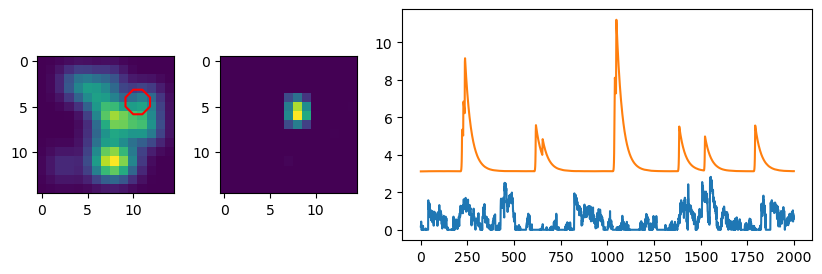

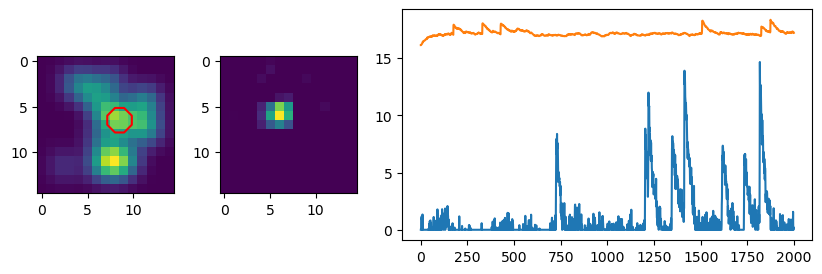

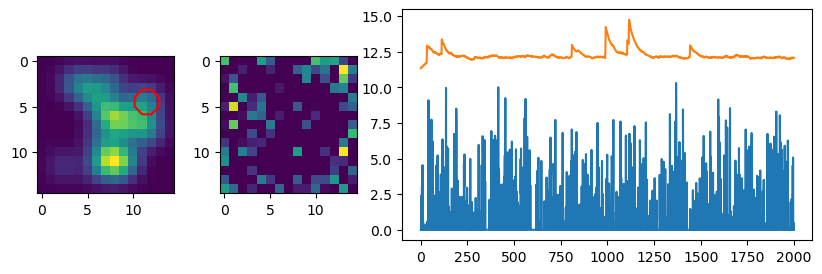

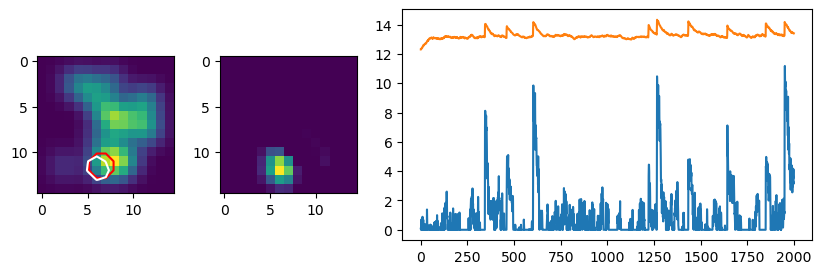

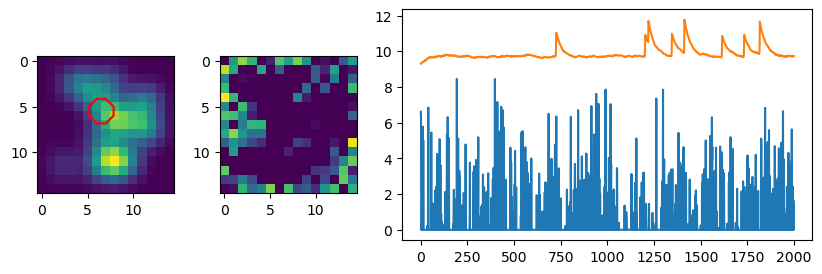

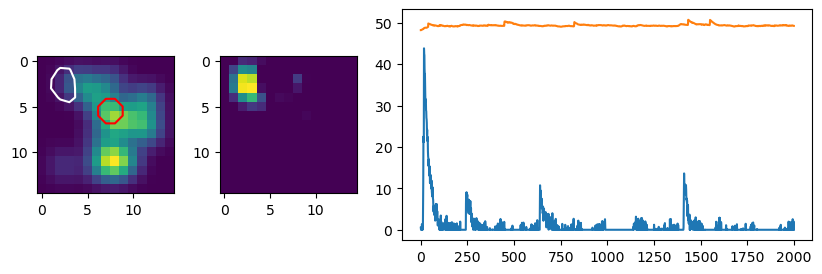

matching_score / truth_score = 0.6094374045888478


In [36]:
matching_score = 0.
truth_score = 0.
if simulation:
    reco_levels = [0.60]
    for src in range(0,n_sources):
        truth_levels = [0.60]
        reco_levels = [0.60*np.max(image_array_by_cov[cluster])]
        fig, ax = plt.subplots(1, 3, figsize=(10, 3), gridspec_kw={'width_ratios': [1, 1, 3]})
        cluster = cluster_matching_by_cov[src][1]
        ax[0].imshow(movie.mean(axis=0))
        ax[0].contour(source_footprints[src], levels=truth_levels, colors='r')
        ax[0].contour(image_array_by_cov[cluster] / np.max(image_array_by_cov[cluster]), levels=reco_levels, colors='w')
        ax[1].imshow(image_array_by_cov[cluster])
        ax[2].plot(S_solved_by_cov[cluster], label="reconstruction")
        ax[2].plot(traces[src] + 1.1*np.max(S_solved_by_cov[cluster]), label="truth")
        # ax[2].legend()
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_by_cov_{fig_label}.png')
        plt.show()

        matching_score += S_solved_by_cov[cluster].T @ traces[src,n_lags*lag_time:]
        truth_score += np.sqrt(traces[src,n_lags*lag_time:].T @ traces[src,n_lags*lag_time:] * S_solved_by_cov[cluster].T @ S_solved_by_cov[cluster])

    print (f"matching_score / truth_score = {matching_score / truth_score}")
else:
    for src in range(0,k):
        reco_levels = [0.30*np.max(image_array_by_cov[src])]
        fig, ax = plt.subplots(1, 3, figsize=(10, 2), gridspec_kw={'width_ratios': [1, 1, 3]})
        ax[0].imshow(movie.mean(axis=0))
        ax[0].contour(image_array_by_cov[src], levels=reco_levels, colors='w')
        ax[1].imshow(image_array_by_cov[src], cmap="Reds")
        ax[2].plot(S_solved_by_cov[src])
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_by_cov_{fig_label}.png')
        plt.show()

In [37]:
from scipy.optimize import linear_sum_assignment

def permute_rows_to_maximize_trace(A):
    """
    Permute the rows of a square matrix A to maximize the trace of the resulting matrix.
    
    Parameters:
        A (numpy.ndarray): Square matrix of shape (n, n)
        
    Returns:
        A_permuted (numpy.ndarray): Matrix with permuted rows
        permutation (numpy.ndarray): The optimal row permutation
        max_trace (float): The maximum trace achieved
    """
    # Convert maximization to minimization by negating the matrix
    cost_matrix = -A
    row_indices, col_indices = linear_sum_assignment(cost_matrix)

    # Apply the optimal row permutation
    A_permuted = A[:, col_indices]
    max_trace = np.trace(A_permuted)
    
    return A_permuted, col_indices, max_trace


max_trace = 0.6756264516651417


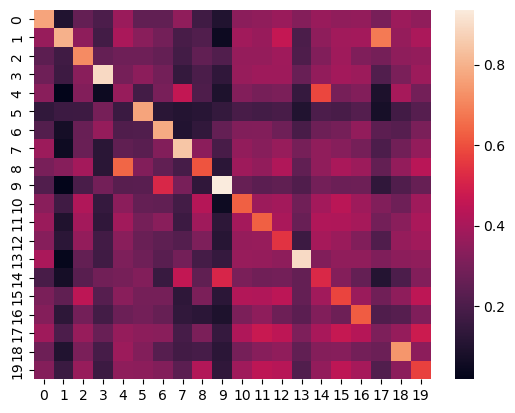

In [38]:
if simulation:
    M_cossim = cosine_similarity(S_sorted_by_sim, traces)
    M_cossim_permute, _, max_trace = permute_rows_to_maximize_trace(M_cossim)
    print (f"max_trace = {max_trace/M_cossim.shape[0]}")
    sns.heatmap(M_cossim_permute)
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/truth_cos_similarity_by_sim.png')

max_trace = 0.7362345717011112


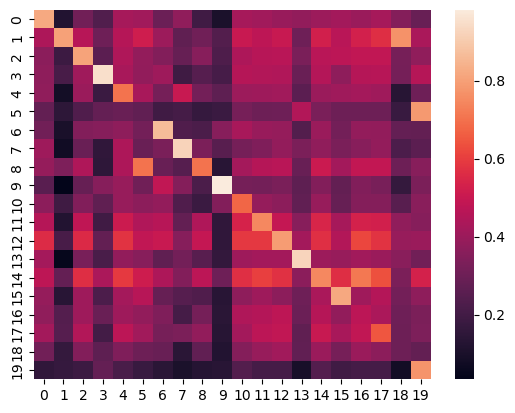

In [39]:
if simulation:
    M_cossim = cosine_similarity(S_sorted_by_cov, traces)
    M_cossim_permute, _, max_trace = permute_rows_to_maximize_trace(M_cossim)
    print (f"max_trace = {max_trace/M_cossim.shape[0]}")
    sns.heatmap(M_cossim_permute)
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/truth_cos_similarity_by_cov.png')

M_cossim_meanoff = 0.10251379382908711


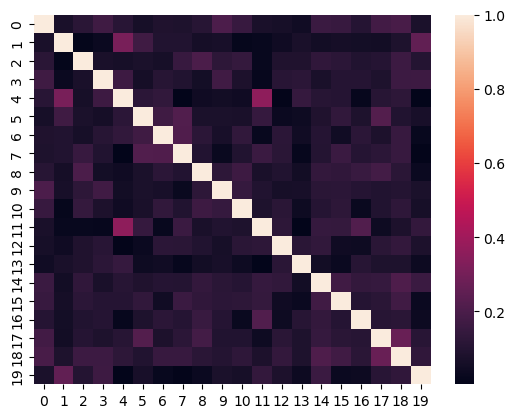

In [40]:
M_cossim = cosine_similarity(S_solved_by_sim, S_solved_by_sim)
M_cossim_dim = M_cossim.shape[0]
M_cossim_trace = np.trace(M_cossim)
M_cossim_meanoff = (np.sum(M_cossim) - M_cossim_trace)/(M_cossim_dim*M_cossim_dim-M_cossim_dim)
print (f"M_cossim_meanoff = {M_cossim_meanoff}")
sns.heatmap(M_cossim)
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/S_cos_similarity_by_sim.png')

M_cossim_meanoff = 0.18293573132323868


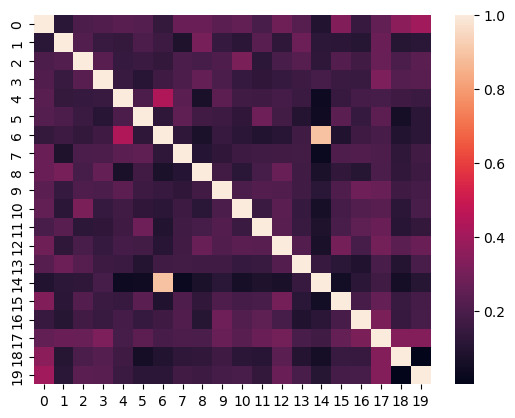

In [41]:
M_cossim = cosine_similarity(S_solved_by_cov, S_solved_by_cov)
M_cossim_dim = M_cossim.shape[0]
M_cossim_trace = np.trace(M_cossim)
M_cossim_meanoff = (np.sum(M_cossim) - M_cossim_trace)/(M_cossim_dim*M_cossim_dim-M_cossim_dim)
print (f"M_cossim_meanoff = {M_cossim_meanoff}")
sns.heatmap(M_cossim)
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/S_cos_similarity_by_cov.png')

M_cossim_meanoff = 0.18238805345327372


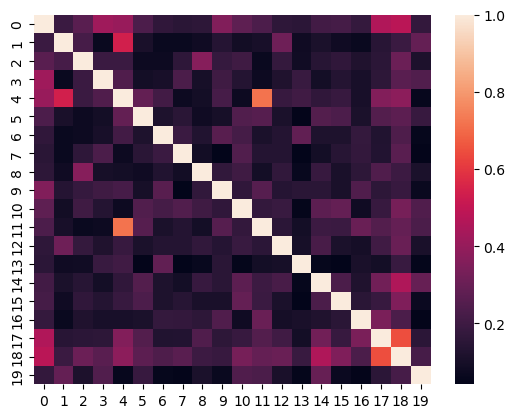

In [42]:
M_cossim = cosine_similarity(A_solved_by_sim.T, A_solved_by_sim.T)
M_cossim_dim = M_cossim.shape[0]
M_cossim_trace = np.trace(M_cossim)
M_cossim_meanoff = (np.sum(M_cossim) - M_cossim_trace)/(M_cossim_dim*M_cossim_dim-M_cossim_dim)
print (f"M_cossim_meanoff = {M_cossim_meanoff}")
sns.heatmap(M_cossim)
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/A_cos_similarity_by_sim.png')

M_cossim_meanoff = 0.0309310138601789


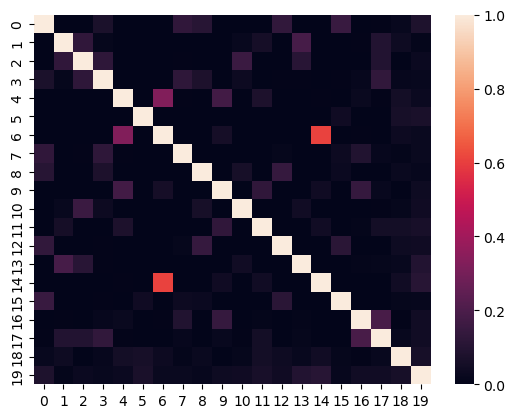

In [43]:
M_cossim = cosine_similarity(A_solved_by_cov.T, A_solved_by_cov.T)
M_cossim_dim = M_cossim.shape[0]
M_cossim_trace = np.trace(M_cossim)
M_cossim_meanoff = (np.sum(M_cossim) - M_cossim_trace)/(M_cossim_dim*M_cossim_dim-M_cossim_dim)
print (f"M_cossim_meanoff = {M_cossim_meanoff}")
sns.heatmap(M_cossim)
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/A_cos_similarity_by_cov.png')